In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:
# Step 2: Load the inbuilt Iris dataset
data = load_iris()

X = data.data

print("Dataset Loaded Successfully")
print("Dataset Shape:", X.shape)


Dataset Loaded Successfully
Dataset Shape: (150, 4)


In [3]:
# Step 3: Data preprocessing
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nData Preprocessing Completed")



Data Preprocessing Completed


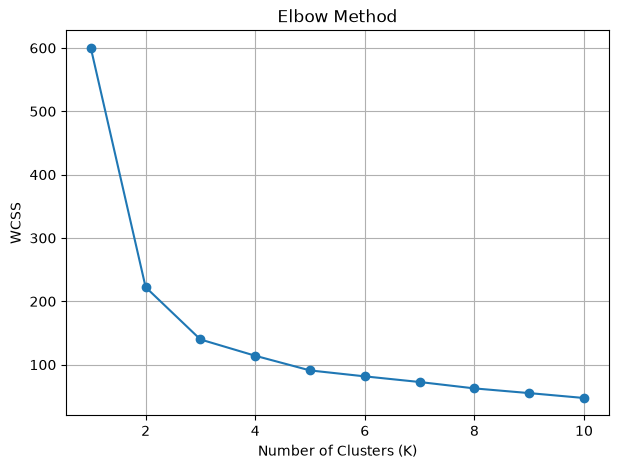

In [4]:
# Step 4: Elbow Method to find optimal K
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow graph
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()


In [5]:
# Step 5: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering Completed")
print("Cluster Labels:")
print(kmeans_labels)




K-Means Clustering Completed
Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


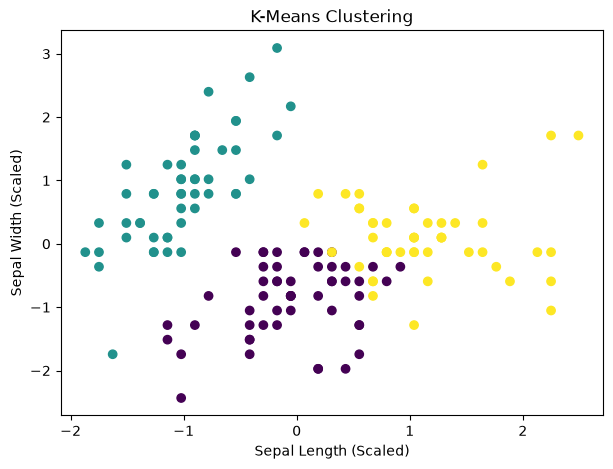

In [6]:
# Step 6: Visualize K-Means Clusters
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)

plt.title("K-Means Clustering")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")

plt.show()


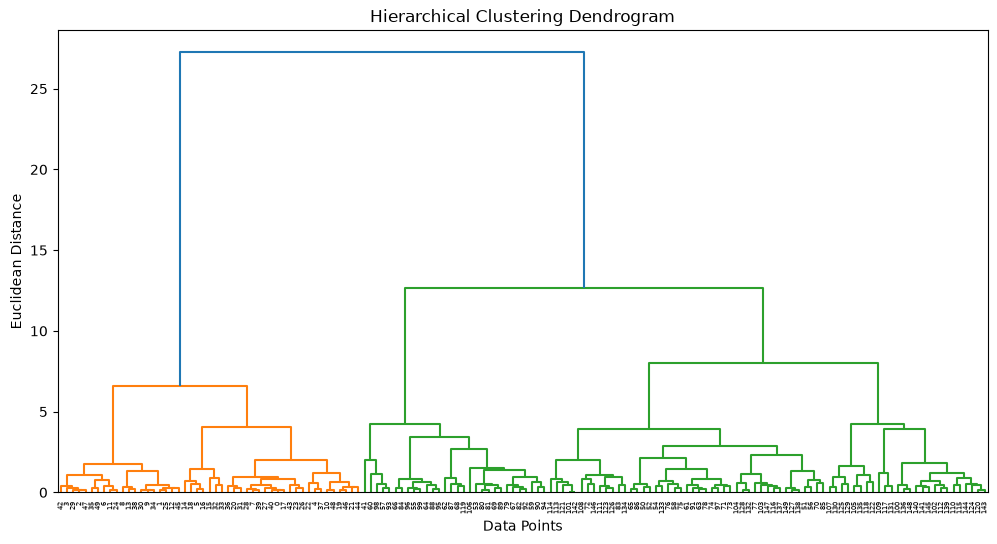

In [7]:
# Step 7: Create Dendrogram
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

In [8]:
# Step 8: Apply Hierarchical Clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hc_labels = hc.fit_predict(X_scaled)

print("\nHierarchical Clustering Completed")
print("Cluster Labels:")
print(hc_labels)


Hierarchical Clustering Completed
Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


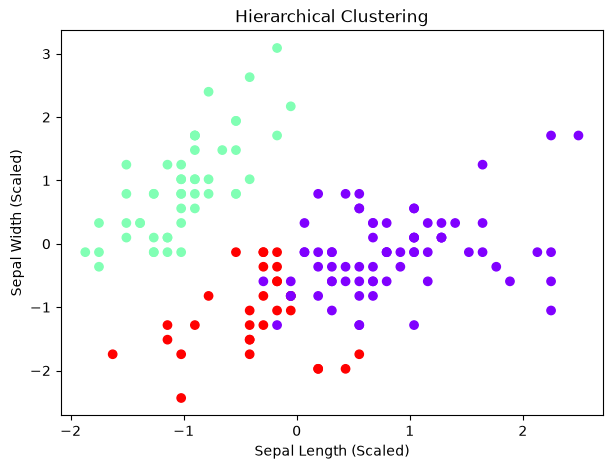

In [9]:


# Step 9: Visualize Hierarchical Clusters
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hc_labels,
    cmap='rainbow'
)

plt.title("Hierarchical Clustering")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")

plt.show()

In [10]:
# Step 10: Display cluster comparison
result = pd.DataFrame({
    "K-Means": kmeans_labels,
    "Hierarchical": hc_labels
})

print("\nCluster Comparison:")
print(result.head(10))



Cluster Comparison:
   K-Means  Hierarchical
0        1             1
1        1             1
2        1             1
3        1             1
4        1             1
5        1             1
6        1             1
7        1             1
8        1             1
9        1             1
